# Data Science Lifecycle – Assignment 1 

**Objective:** apply exploratory data analysis (EDA) and statistical techniques to the `automobileEDA.csv` dataset to identify the key variables that drive car **price**.

**Main variables**: technical specs, brand, body/drive configuration, fuel economy, price.

---
## Question 1 – Explore features, check missing values, duplicates, outliers 
### 1.1 Load and inspect structure

In [ ]:
raw = pd.read_csv('automobileEDA.csv')
df = raw.copy()
print('Shape:', df.shape)
df.info()
display(df.head())

Shape: (201, 29)
<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-system        2

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


Column notes: `length` and `width` are **already scaled** (0–1, relative to the longest/widest car); `height`, `wheel-base` are in inches; `curb-weight` in lb; `city-L/100km` is just a unit conversion of `city-mpg`; `diesel`/`gas` are dummy variables for fuel type (perfectly complementary); `horsepower-binned` is derived from `horsepower`. These redundancies matter later for feature selection.

### 1.2 Missing values and duplicates

In [ ]:
miss = df.isna().sum(); display(miss[miss > 0].to_frame('missing values'))
display(df[df.isna().any(axis=1)][['make','body-style','engine-type','engine-size','bore','stroke','horsepower','horsepower-binned','price']])
print('Exact duplicate rows            :', df.duplicated().sum())
print('Duplicates if price is ignored  :', df.drop(columns='price').duplicated().sum(), '(same spec, different price -> distinct listings, kept)')

# Hidden placeholders: values that look like earlier mean-imputation (one value repeated many times)
print()
for c, v in [('normalized-losses', 122), ('horsepower', 104.256157635468), ('peak-rpm', 5125.369458128079), ('bore', 3.329751243781096)]:
    print(f'{c:18s}: {(np.isclose(df[c], v)).sum():3d} rows equal {v:.3f}')

,missing values
stroke,4
horsepower-binned,1


,make,body-style,engine-type,engine-size,bore,stroke,horsepower,horsepower-binned,price
46,jaguar,sedan,ohcv,326,3.540000,2.76,262.0,NaN,36000.0
52,mazda,hatchback,rotor,70,3.329751,NaN,101.0,Low,10945.0
53,mazda,hatchback,rotor,70,3.329751,NaN,101.0,Low,11845.0
54,mazda,hatchback,rotor,70,3.329751,NaN,101.0,Low,13645.0
55,mazda,hatchback,rotor,80,3.329751,NaN,135.0,Medium,15645.0


Exact duplicate rows            : 0
Duplicates if price is ignored  : 7 (same spec, different price -> distinct listings, kept)

normalized-losses :  41 rows equal 122.000
horsepower        :   2 rows equal 104.256
peak-rpm          :   2 rows equal 5125.369
bore              :   4 rows equal 3.330


### 1.3 Data-entry errors (inconsistent bore / stroke)
Missing values are not the only quality problem. Cars with the *same make, engine size, engine type and fuel system* should have the same bore and stroke. I compare each row to the median of its siblings and flag deviations above 20%.

In [ ]:
key = ['make','engine-size','engine-type','fuel-system']
chk = df[key + ['bore','stroke']].copy()
for c in ['bore','stroke']:
    chk[c+'_sibling_median'] = df.groupby(key)[c].transform('median')
    chk[c+'_dev'] = (df[c] - chk[c+'_sibling_median']).abs() / chk[c+'_sibling_median']
flag = chk[(chk['bore_dev'] > 0.2) | (chk['stroke_dev'] > 0.2)]
display(flag.round(3))

,make,engine-size,engine-type,fuel-system,bore,stroke,bore_sibling_median,bore_dev,stroke_sibling_median,stroke_dev
108,peugot,120,l,mpfi,3.46,2.19,3.46,0.000,3.19,0.313
110,peugot,120,l,mpfi,3.46,2.19,3.46,0.000,3.19,0.313
130,saab,121,ohc,mpfi,2.54,2.07,3.54,0.282,3.07,0.326


In [ ]:
# Replace flagged cells with the sibling median (typos: stroke 2.19 -> 3.19, bore 2.54 -> 3.54, stroke 2.07 -> 3.07)
for c in ['bore', 'stroke']:
    bad = chk[c + '_dev'] > 0.2
    df.loc[bad, c] = chk.loc[bad, c + '_sibling_median']
print('Corrected cells:', int(((chk.bore_dev > 0.2).sum()) + (chk.stroke_dev > 0.2).sum()))

# Missing stroke (4 Mazda rotary engines; rotary engines have no conventional stroke) -> median imputation
med_stroke = df['stroke'].median()
df['stroke'] = df['stroke'].fillna(med_stroke)
print('Stroke median used for imputation:', med_stroke)

# Missing horsepower-binned (Jaguar, 262 hp): its horsepower is above every car already labelled High
print('Highest hp among rows labelled Medium:', df.loc[df['horsepower-binned']=='Medium','horsepower'].max(),
      '| lowest hp labelled High:', df.loc[df['horsepower-binned']=='High','horsepower'].min(), '| missing row hp:',
      df.loc[df['horsepower-binned'].isna(),'horsepower'].iloc[0])
df['horsepower-binned'] = df['horsepower-binned'].fillna('High')
print('Remaining missing values:', int(df.isna().sum().sum()))

Corrected cells: 4
Stroke median used for imputation: 3.29
Highest hp among rows labelled Medium: 155.0 | lowest hp labelled High: 156.0 | missing row hp: 262.0
Remaining missing values: 0


**What I found and did**

| Issue | Finding | Treatment |
|---|---|---|
| Missing `stroke` | 4 cars (all Mazda rotary engines, which have no conventional stroke) | Filled with the median stroke (3.29) |
| Missing `horsepower-binned` | 1 car (Jaguar, 262 hp) | Filled with **High**: its horsepower is far above every car already labelled High (lowest is 156 hp) |
| Exact duplicates | **0** | Nothing to remove |
| Near-duplicates | 7 rows share every spec but differ in price | Kept: they are different listings and the price differs |
| Data-entry errors | 3 cars have a bore or stroke far from identical-engine siblings (2 Peugeot strokes of 2.19, a Saab bore 2.54 and stroke 2.07) | 4 cells replaced by the sibling value (3.19, 3.54, 3.07) |
| Hidden imputation | 41 cars (20%) have `normalized-losses` = 122 exactly; 2 Renault rows have mean-filled `horsepower`/`peak-rpm` | Kept, but I treat `normalized-losses` with caution (it is also a weak predictor, r = 0.13) |

After cleaning there are **0 missing values** and 0 duplicates.

### 1.4 Outliers (IQR rule: outside Q1 − 1.5·IQR … Q3 + 1.5·IQR)

,lower fence,upper fence,min,max,n outliers,% of rows
variable,,,,,,
normalized-losses,47.00,191.00,65.00,256.00,8,4.0
wheel-base,82.65,114.25,86.60,120.90,3,1.5
length,0.68,1.00,0.68,1.00,1,0.5
width,0.84,0.98,0.84,1.00,11,5.5
height,46.75,60.75,47.80,59.80,0,0.0
curb-weight,1033.50,4061.50,1488.00,4066.00,2,1.0
engine-size,33.50,205.50,61.00,326.00,10,5.0
bore,2.50,4.23,2.68,3.94,0,0.0
stroke,2.76,3.80,2.36,4.17,23,11.4


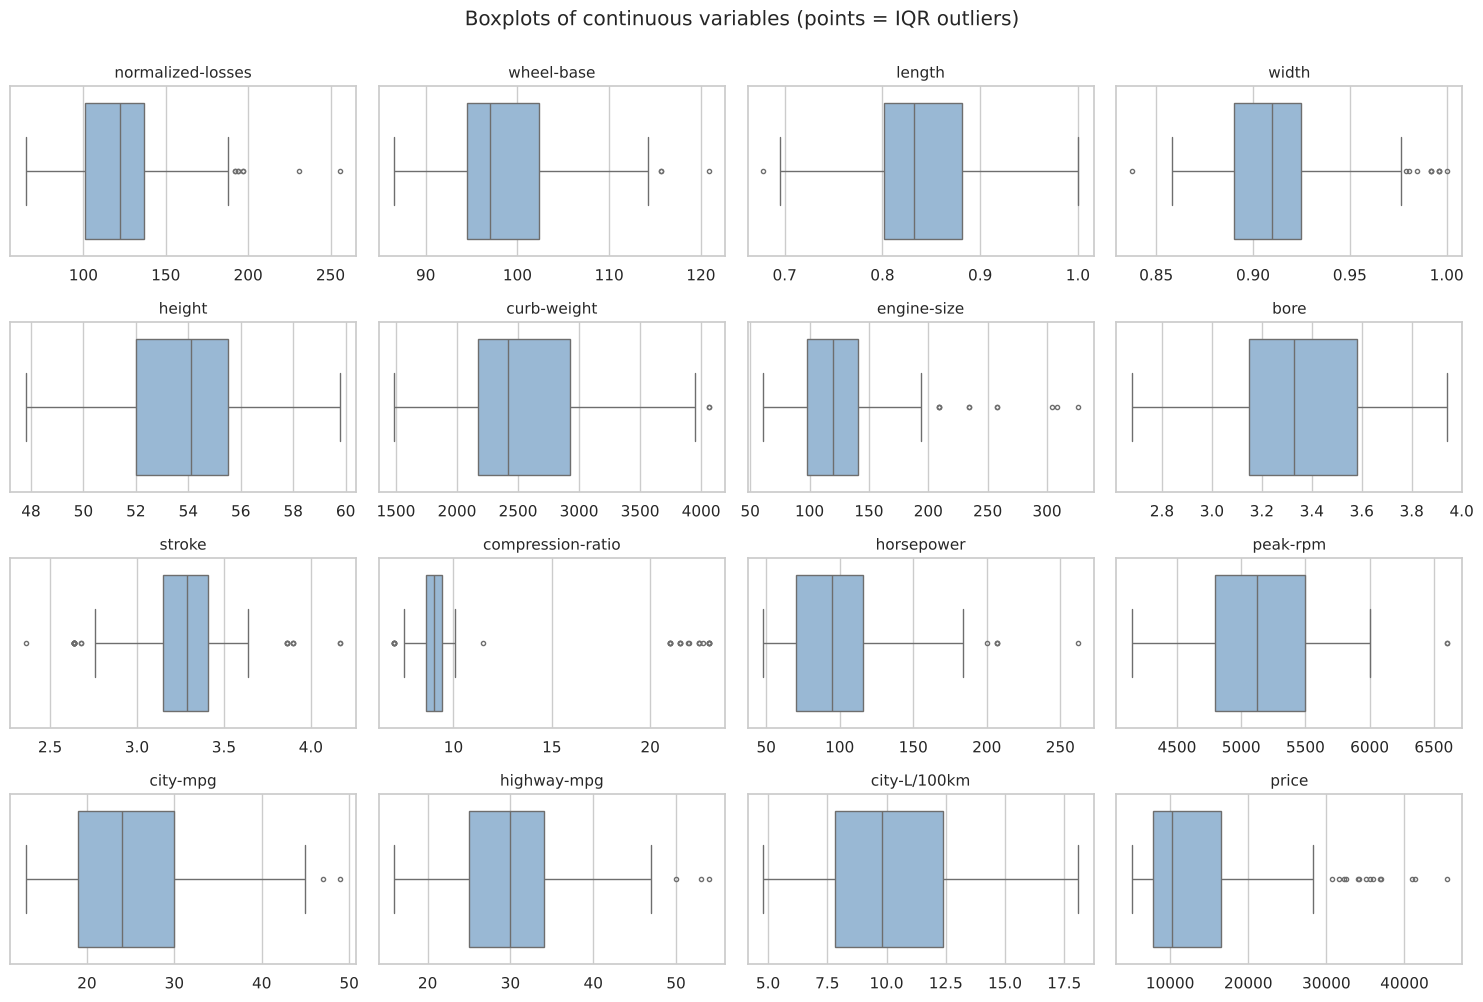

In [ ]:
def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

rows = []
for c in CONT:
    lo, hi = iqr_bounds(df[c]); n = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append([c, round(lo, 2), round(hi, 2), df[c].min().round(2), df[c].max().round(2), n, round(100 * n / len(df), 1)])
out_tbl = pd.DataFrame(rows, columns=['variable','lower fence','upper fence','min','max','n outliers','% of rows']).set_index('variable')
display(out_tbl)

fig, axes = plt.subplots(4, 4, figsize=(15, 10))
for ax, c in zip(axes.ravel(), CONT):
    sns.boxplot(x=df[c], ax=ax, color='#8fb8de', fliersize=3); ax.set_title(c); ax.set_xlabel('')
plt.suptitle('Boxplots of continuous variables (points = IQR outliers)', y=1.0); plt.tight_layout(); plt.show()

In [ ]:
lo, hi = iqr_bounds(df['price'])
display(df.loc[df['price'] > hi, ['make','body-style','engine-size','horsepower','price']].sort_values('price', ascending=False))
print('Compression-ratio outliers by fuel type:')
lo_c, hi_c = iqr_bounds(df['compression-ratio'])
display(pd.crosstab(df['compression-ratio'] > hi_c, np.where(df['diesel'] == 1, 'diesel', 'gas'), rownames=['CR outlier']))

# Sensitivity check: do price outliers distort the main relationships?
core = ['engine-size', 'curb-weight', 'horsepower', 'city-mpg']
no_out = df[df['price'] <= hi]
sens = pd.DataFrame({'r with price (all 201 cars)': [df[c].corr(df['price']) for c in core],
                     'r with price (outliers removed)': [no_out[c].corr(no_out['price']) for c in core]}, index=core).round(3)
display(sens)

,make,body-style,engine-size,horsepower,price
71,mercedes-benz,hardtop,304,184.0,45400.0
15,bmw,sedan,209,182.0,41315.0
70,mercedes-benz,sedan,308,184.0,40960.0
125,porsche,convertible,194,207.0,37028.0
16,bmw,sedan,209,182.0,36880.0
46,jaguar,sedan,326,262.0,36000.0
45,jaguar,sedan,258,176.0,35550.0
69,mercedes-benz,convertible,234,155.0,35056.0
68,mercedes-benz,sedan,234,155.0,34184.0
124,porsche,hardtop,194,207.0,34028.0


Compression-ratio outliers by fuel type:


col_0,diesel,gas
CR outlier,,
False,0,180
True,20,1


,r with price (all 201 cars),r with price (outliers removed)
engine-size,0.872,0.750
curb-weight,0.834,0.855
horsepower,0.810,0.722
city-mpg,-0.687,-0.671


**Outlier assessment (IQR rule)**

- **Price:** 14 cars (7%) are above the upper fence of about 29,600. All are Mercedes-Benz, BMW, Porsche or Jaguar, so they are genuine luxury cars, not errors.
- **Compression ratio:** 21 cars are above the upper fence (20 of them diesel, whose compression ratio is naturally 21–23); a further 6 gas turbo engines (all at 7.0) fall just under the lower fence. Genuine engineering differences.
- **Engine size, width, horsepower, curb weight:** the flagged cars are again the big-engined luxury models. **Stroke** has a very narrow IQR, so 23 mild outliers are just ordinary engines.

**Decision: no rows removed or capped.** The extreme values are real, the dataset is small (201 rows), and high-priced cars are exactly what a dealer needs to price. Instead I handle them with robust methods later (Spearman correlation, Kruskal–Wallis, log-price).

**Sensitivity check:** removing the 14 expensive cars lowers the correlation of price with engine-size (0.87 → 0.75) and horsepower (0.81 → 0.72), but curb-weight stays strong (0.83 → 0.86) and city-mpg is stable. So the luxury cars strengthen the engine-size/horsepower relationships, while **curb weight is the most robust signal**.

### 1.5 Save the cleaned dataset

In [ ]:
df_clean = df.copy()
assert df_clean.isna().sum().sum() == 0 and df_clean.duplicated().sum() == 0
df_clean.to_csv('YourLastName_Data.csv', index=False)
print('Saved YourLastName_Data.csv ->', df_clean.shape)

changes = pd.DataFrame({'before': raw.isna().sum(), 'after': df_clean.isna().sum()}); display(changes[changes.sum(axis=1) > 0])
df = df_clean.copy()
df['fuel-type'] = np.where(df['diesel'] == 1, 'diesel', 'gas')   # readable label for later plots (analysis copy only)
CATS = ['make','aspiration','num-of-doors','body-style','drive-wheels','engine-location','engine-type',
        'num-of-cylinders','fuel-system','fuel-type','horsepower-binned','symboling']

Saved YourLastName_Data.csv -> (201, 29)


,before,after
stroke,4,0
horsepower-binned,1,0


The cleaned dataset is saved as `YourLastName_Data.csv` (201 rows × 29 columns, no missing values, no duplicates). Only `stroke`, `bore` and `horsepower-binned` values were changed. *(Rename the file and the notebook with your real surname before submitting.)*

---
## Question 2 – Descriptive statistics and distributions
### 2.1 Summary statistics – continuous variables

In [ ]:
desc = df[CONT].describe().T
desc['skew'] = df[CONT].skew(); desc['kurtosis'] = df[CONT].kurt(); desc['CV %'] = 100 * desc['std'] / desc['mean']
display(desc.round(3))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,CV %
normalized-losses,201.0,122.000,31.996,65.000,101.000,122.000,137.000,256.000,0.847,1.319,26.226
wheel-base,201.0,98.797,6.066,86.600,94.500,97.000,102.400,120.900,1.031,0.948,6.140
length,201.0,0.837,0.059,0.678,0.802,0.832,0.882,1.000,0.154,-0.065,7.074
width,201.0,0.915,0.029,0.837,0.890,0.910,0.925,1.000,0.875,0.679,3.189
height,201.0,53.767,2.448,47.800,52.000,54.100,55.500,59.800,0.029,-0.433,4.553
curb-weight,201.0,2555.667,517.297,1488.000,2169.000,2414.000,2926.000,4066.000,0.706,0.035,20.241
engine-size,201.0,126.876,41.547,61.000,98.000,120.000,141.000,326.000,1.979,5.497,32.746
bore,201.0,3.336,0.263,2.680,3.150,3.330,3.580,3.940,0.048,-1.031,7.871
stroke,201.0,3.272,0.285,2.360,3.150,3.290,3.410,4.170,-0.228,1.217,8.721
compression-ratio,201.0,10.164,4.005,7.000,8.600,9.000,9.400,23.000,2.584,5.069,39.402


### 2.2 Frequency counts – categorical variables

In [ ]:
for c in CATS:
    vc = df[c].value_counts(); t = pd.DataFrame({'count': vc, 'percent': (100 * vc / len(df)).round(1)})
    print(f'--- {c} ({df[c].nunique()} levels) ---'); display(t.T if len(t) > 8 else t)

--- make (22 levels) ---


make,toyota,nissan,mazda,honda,mitsubishi,subaru,volkswagen,peugot,volvo,dodge,bmw,mercedes-benz,plymouth,audi,saab,porsche,alfa-romero,chevrolet,jaguar,isuzu,renault,mercury
count,32.0,18.0,17.0,13.0,13.0,12.0,12.0,11.0,11.0,9.0,8.0,8.0,7.0,6.0,6.0,4.0,3.0,3.0,3.0,2.0,2.0,1.0
percent,15.9,9.0,8.5,6.5,6.5,6.0,6.0,5.5,5.5,4.5,4.0,4.0,3.5,3.0,3.0,2.0,1.5,1.5,1.5,1.0,1.0,0.5


--- aspiration (2 levels) ---


,count,percent
aspiration,,
std,165,82.1
turbo,36,17.9


--- num-of-doors (2 levels) ---


,count,percent
num-of-doors,,
four,115,57.2
two,86,42.8


... (14 outputs left out)

--- horsepower-binned (3 levels) ---


,count,percent
horsepower-binned,,
Low,115,57.2
Medium,62,30.8
High,24,11.9


--- symboling (6 levels) ---


,count,percent
symboling,,
0,65,32.3
1,52,25.9
2,32,15.9
3,27,13.4
-1,22,10.9
-2,3,1.5


**Continuous variables**

- **Price** has mean 13,207 but median 10,295, standard deviation 7,947 (coefficient of variation 60%) and range 5,118–45,400: it is **right-skewed** (skew 1.81), pulled up by a small group of luxury cars.
- Other strongly right-skewed variables: `compression-ratio` (2.58, two clusters: gas ≈ 7–10, diesel ≈ 21–23), `engine-size` (1.98), `horsepower` (1.15) and `wheel-base` (1.03).
- Roughly symmetric: `height`, `peak-rpm`, `length`, `bore`.
- Typical car: about 2,400 lb, a 120-cubic-inch engine, 95 hp and 24 city mpg (medians).

**Categorical variables**

- The sample is dominated by **gas (90%)**, **standard aspiration (82%)**, **front engine (98.5%)**, **four cylinders (78%)**, **ohc engines (72%)** and **front-wheel drive (59%)**. Sedans (47%) and hatchbacks (34%) make up most bodies.
- **Toyota** has 32 cars (16%); 22 makes appear in total, several with only 1–3 cars (e.g. Mercury has 1), so make-level averages for rare brands are unreliable. Likewise rear engine (3 cars), 3 or 12 cylinders (1 car each) and `mfi`/`spfi` fuel systems (1 car each) are too rare to generalise from.

### 2.3 Distribution of price

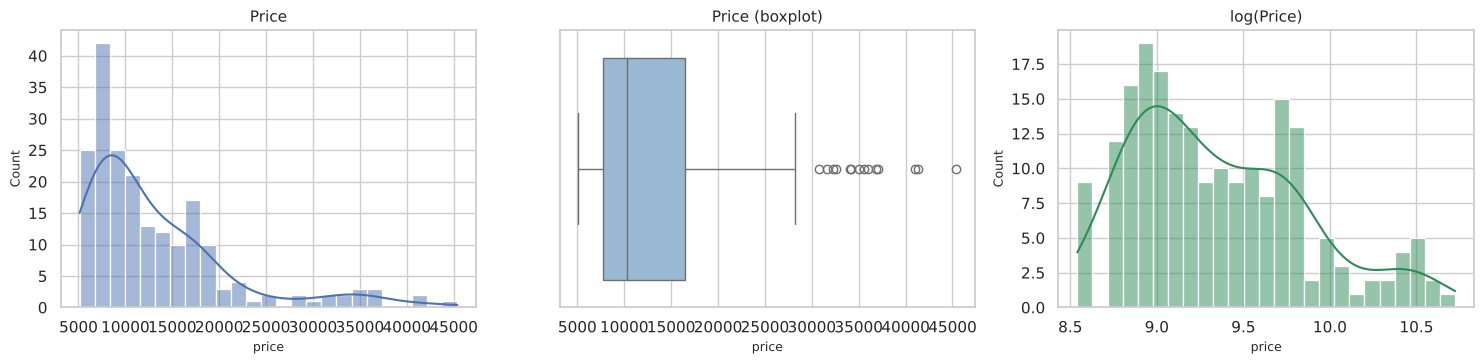

Price skew = 1.81; log(price) skew = 0.68
Mean = 13,207, Median = 10,295


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(df['price'], kde=True, bins=25, ax=ax[0]); ax[0].set_title('Price')
sns.boxplot(x=df['price'], ax=ax[1], color='#8fb8de'); ax[1].set_title('Price (boxplot)')
sns.histplot(np.log(df['price']), kde=True, bins=25, ax=ax[2], color='seagreen'); ax[2].set_title('log(Price)')
plt.tight_layout(); plt.show()
print(f"Price skew = {df['price'].skew():.2f}; log(price) skew = {np.log(df['price']).skew():.2f}")
print(f"Mean = {df['price'].mean():,.0f}, Median = {df['price'].median():,.0f}")

### 2.4 Distribution of the other continuous variables

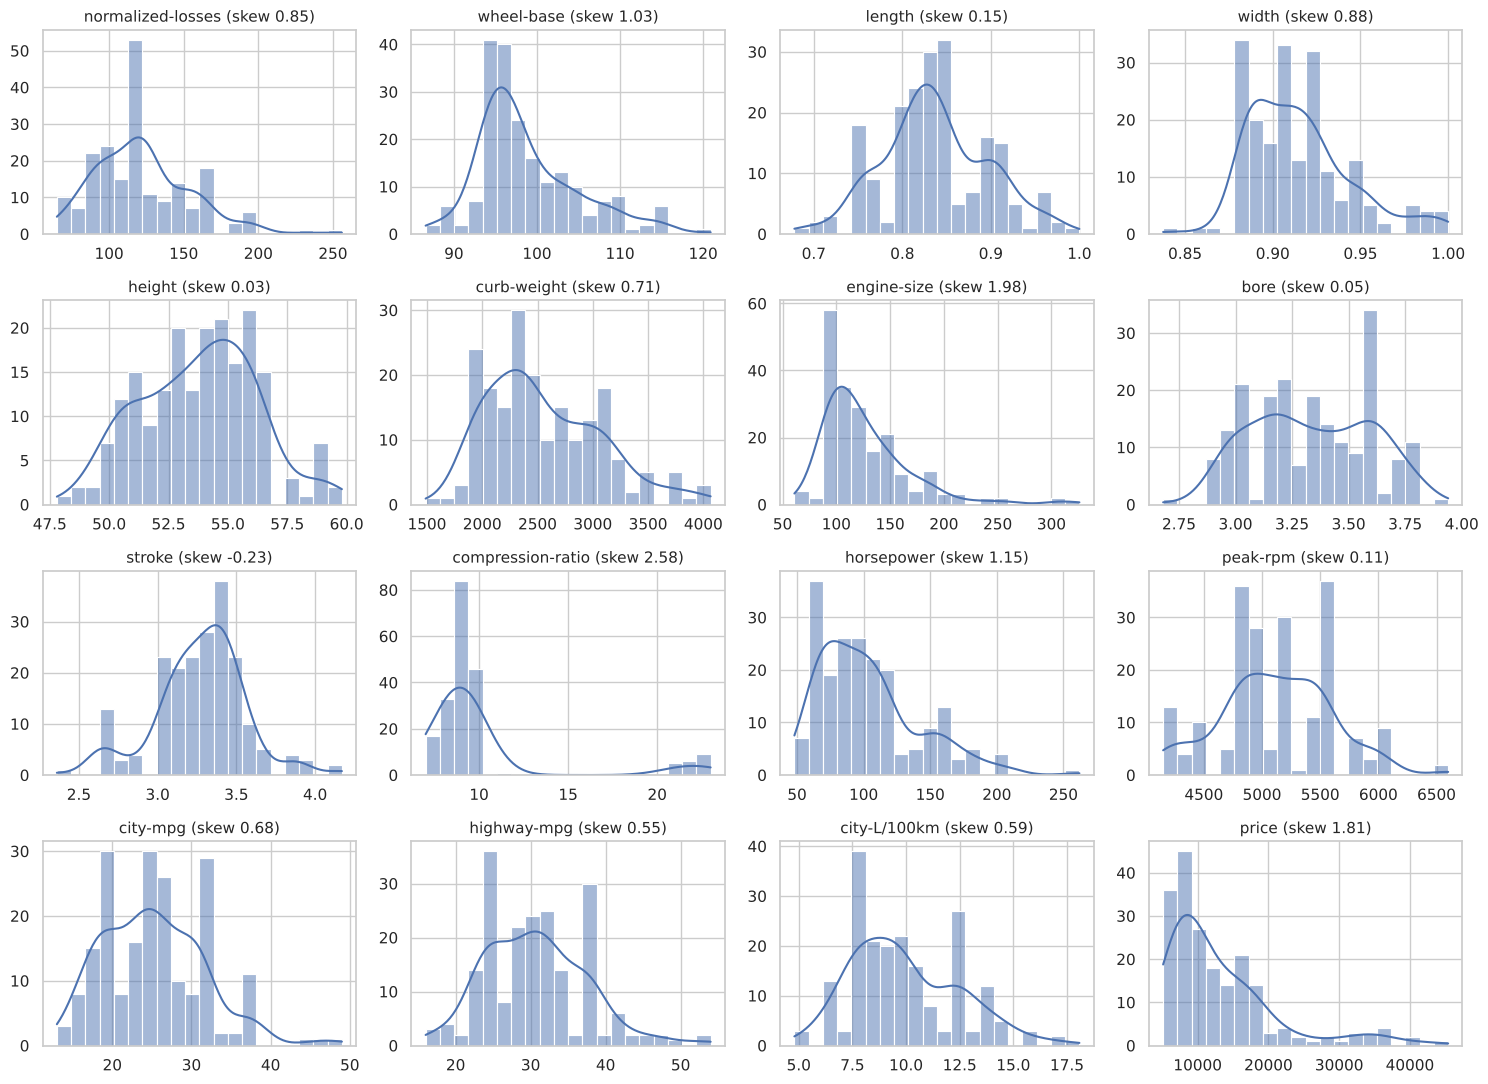

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, c in zip(axes.ravel(), CONT):
    sns.histplot(df[c], kde=True, bins=20, ax=ax); ax.set_title(f'{c} (skew {df[c].skew():.2f})'); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

### 2.5 Distribution of categorical variables

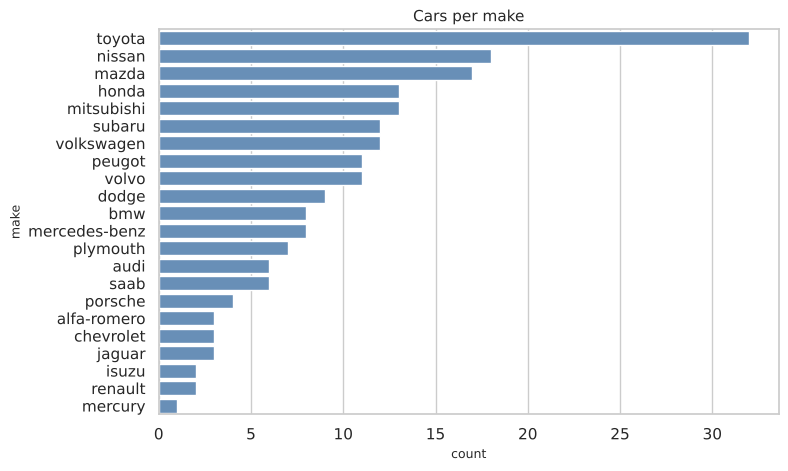

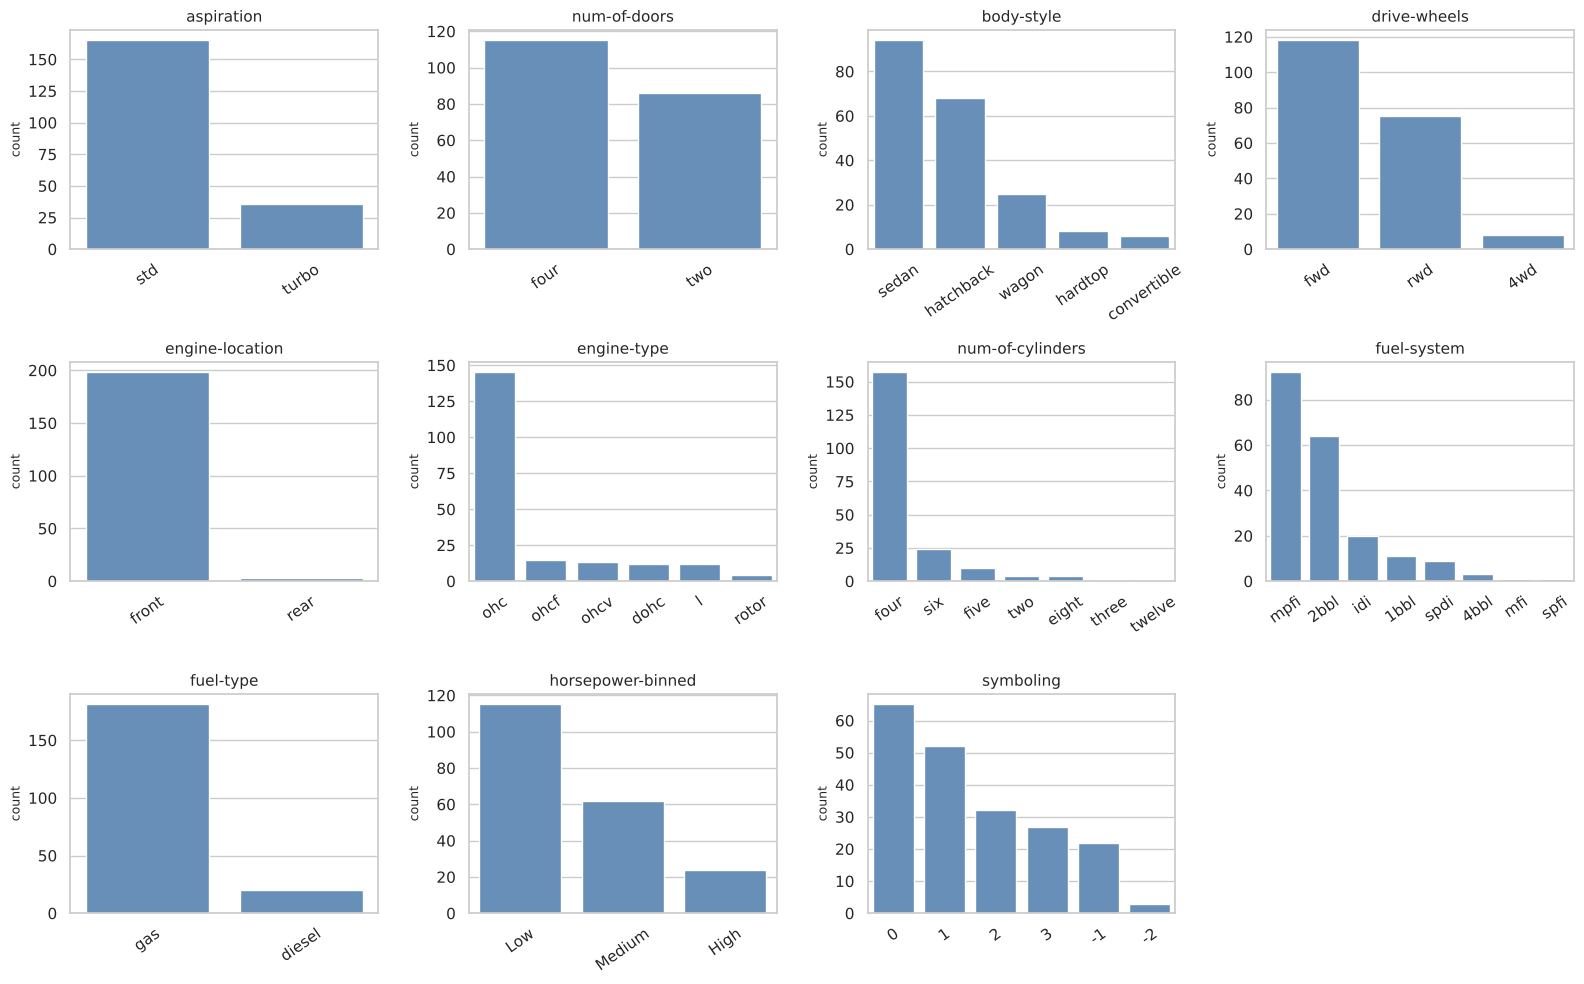

In [ ]:
plt.figure(figsize=(8, 5)); order = df['make'].value_counts().index
sns.countplot(y='make', data=df, order=order, color='#5b8fc4'); plt.title('Cars per make'); plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 10)); others = [c for c in CATS if c != 'make']
for ax, c in zip(axes.ravel(), others):
    sns.countplot(x=c, data=df, ax=ax, order=df[c].value_counts().index, color='#5b8fc4'); ax.set_title(c); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=35)
for ax in axes.ravel()[len(others):]: ax.axis('off')
plt.tight_layout(); plt.show()

**Patterns observed**

1. **Price is right-skewed**: most cars cost 5,000–16,500 (the interquartile range is 7,775–16,500) with a long tail up to 45,400. Taking logs reduces the skew from 1.81 to 0.68, so `log(price)` is better behaved for linear models.
2. Size and power variables (`engine-size`, `horsepower`, `curb-weight`, `wheel-base`) share the same shape as price: many small, light, low-power cars and a thin tail of large ones. This foreshadows strong positive relationships with price.
3. `compression-ratio` is **bimodal** because of diesel engines; `height`, `peak-rpm` and `length` are close to symmetric.
4. The categorical bar charts confirm the heavy imbalance (mostly gas, front-engine, four-cylinder, ohc, front-wheel-drive cars), which is why a few rare levels cannot support firm conclusions.

---
## Question 3 – Average price by group 
### 3.1 Drive-wheels and body-style

,count,mean,median,std,min,max
drive-wheels,,,,,,
rwd,75,19758.0,16900.0,9083.0,6785.0,45400.0
4wd,8,10241.0,9006.0,3288.0,7603.0,17450.0
fwd,118,9245.0,8192.0,3346.0,5118.0,23875.0


,count,mean,median,std,min,max
body-style,,,,,,
hardtop,8,22208.0,19688.0,14556.0,8249.0,45400.0
convertible,6,21890.0,17084.0,11188.0,11595.0,37028.0
sedan,94,14460.0,11078.0,8523.0,5499.0,41315.0
wagon,25,12372.0,11694.0,5121.0,6918.0,28248.0
hatchback,68,9957.0,8672.0,4149.0,5118.0,22018.0


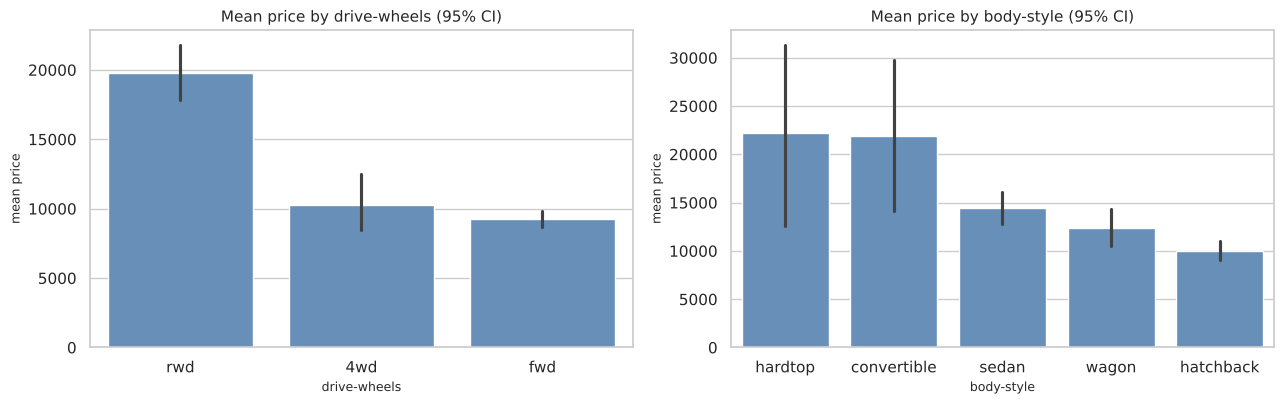

drive-wheels  highest: rwd (19,758, n=75) | lowest: fwd (9,245, n=118)
body-style    highest: hardtop (22,208, n=8) | lowest: hatchback (9,957, n=68)


In [ ]:
def group_summary(by):
    return (df.groupby(by)['price'].agg(count='count', mean='mean', median='median', std='std', min='min', max='max')
              .round(0).sort_values('mean', ascending=False))

g_drive = group_summary('drive-wheels'); g_body = group_summary('body-style')
display(g_drive); display(g_body)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.barplot(x='drive-wheels', y='price', data=df, order=g_drive.index, errorbar=('ci', 95), ax=ax[0], color='#5b8fc4')
ax[0].set_title('Mean price by drive-wheels (95% CI)')
sns.barplot(x='body-style', y='price', data=df, order=g_body.index, errorbar=('ci', 95), ax=ax[1], color='#5b8fc4')
ax[1].set_title('Mean price by body-style (95% CI)')
for a in ax: a.set_ylabel('mean price')
plt.tight_layout(); plt.show()

for name, g in [('drive-wheels', g_drive), ('body-style', g_body)]:
    print(f"{name:13s} highest: {g.index[0]} ({g['mean'].iloc[0]:,.0f}, n={int(g['count'].iloc[0])}) | lowest: {g.index[-1]} ({g['mean'].iloc[-1]:,.0f}, n={int(g['count'].iloc[-1])})")

### 3.2 Drive-wheels × body-style combinations

drive-wheels,4wd,fwd,rwd
body-style,,,
convertible,NaN,11595.0,23950.0
hardtop,NaN,8249.0,24203.0
hatchback,7603.0,8396.0,14338.0
sedan,12647.0,9812.0,21712.0
wagon,9096.0,9997.0,16994.0


drive-wheels,4wd,fwd,rwd
n cars,,,
convertible,0,1,5
hardtop,0,1,7
hatchback,1,49,18
sedan,3,55,36
wagon,4,12,9


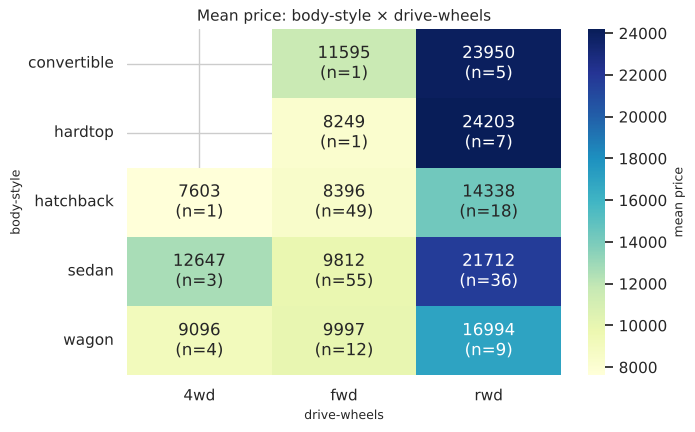

,,count,mean,median,std,min,max
body-style,drive-wheels,,,,,,
hardtop,rwd,7,24203.0,28176.0,14493.0,8449.0,45400.0
convertible,rwd,5,23950.0,17669.0,11165.0,13495.0,37028.0
sedan,rwd,36,21712.0,18382.0,9195.0,6785.0,41315.0
wagon,rwd,9,16994.0,16515.0,4687.0,12440.0,28248.0
hatchback,rwd,18,14338.0,14645.0,3832.0,8238.0,22018.0
sedan,4wd,3,12647.0,11259.0,4281.0,9233.0,17450.0
convertible,fwd,1,11595.0,11595.0,NaN,11595.0,11595.0
wagon,fwd,12,9997.0,8921.0,3584.0,6918.0,18920.0
sedan,fwd,55,9812.0,8558.0,3520.0,5499.0,23875.0


Highest combination (n>=5): ('hardtop', 'rwd') 24,203
Lowest  combination (n>=5): ('hatchback', 'fwd') 8,396


In [ ]:
pv = df.pivot_table(values='price', index='body-style', columns='drive-wheels', aggfunc='mean').round(0)
cnt = df.pivot_table(values='price', index='body-style', columns='drive-wheels', aggfunc='count')
display(pv); display(cnt.fillna(0).astype(int).rename_axis('n cars'))

plt.figure(figsize=(7, 4.5))
annot = pv.round(0).fillna(0).astype(int).astype(str) + '\n(n=' + cnt.fillna(0).astype(int).astype(str) + ')'
annot = annot.where(pv.notna(), 'no cars')
sns.heatmap(pv, annot=annot.values, fmt='', cmap='YlGnBu', cbar_kws={'label': 'mean price'}); plt.title('Mean price: body-style × drive-wheels'); plt.show()

combo = group_summary(['body-style', 'drive-wheels']); display(combo)
solid = combo[combo['count'] >= 5]
print('Highest combination (n>=5):', solid.index[0], f"{solid['mean'].iloc[0]:,.0f}")
print('Lowest  combination (n>=5):', solid.index[-1], f"{solid['mean'].iloc[-1]:,.0f}")

### 3.3 Other grouping parameters (make, cylinders, aspiration, engine location, fuel type)

,count,mean,median,std,min,max
make,,,,,,
jaguar,3,34600.0,35550.0,2048.0,32250.0,36000.0
mercedes-benz,8,33647.0,32892.0,6790.0,25552.0,45400.0
porsche,4,31400.0,33278.0,6529.0,22018.0,37028.0
bmw,8,26119.0,22835.0,9264.0,16430.0,41315.0
volvo,11,18063.0,18420.0,3315.0,12940.0,22625.0
audi,6,17859.0,17580.0,3452.0,13950.0,23875.0
mercury,1,16503.0,16503.0,NaN,16503.0,16503.0
alfa-romero,3,15498.0,16500.0,1735.0,13495.0,16500.0
peugot,11,15489.0,16630.0,2247.0,11900.0,18150.0


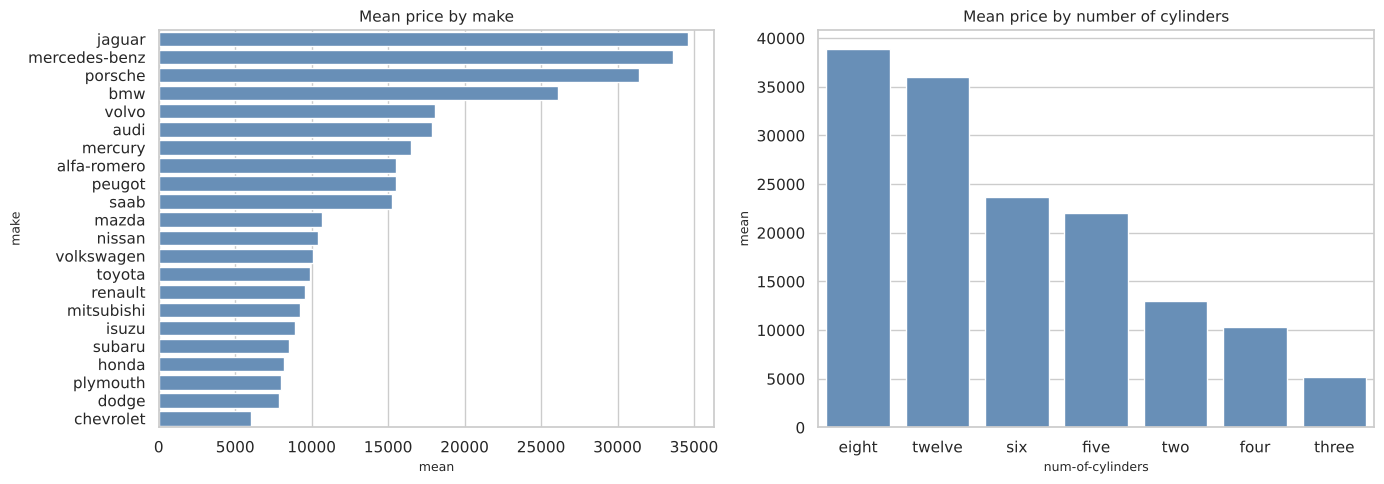

aspiration


,count,mean,median,std,min,max
aspiration,,,,,,
turbo,36,16255.0,15686.0,6180.0,7689.0,31600.0
std,165,12542.0,9538.0,8148.0,5118.0,45400.0


engine-location


,count,mean,median,std,min,max
engine-location,,,,,,
rear,3,34528.0,34028.0,2291.0,32528.0,37028.0
front,198,12884.0,10222.0,7552.0,5118.0,45400.0


fuel-type


,count,mean,median,std,min,max
fuel-type,,,,,,
diesel,20,15838.0,13852.0,7760.0,7099.0,31600.0
gas,181,12916.0,9989.0,7935.0,5118.0,45400.0


num-of-doors


,count,mean,median,std,min,max
num-of-doors,,,,,,
four,115,13498.0,10898.0,7340.0,6229.0,40960.0
two,86,12818.0,9927.0,8722.0,5118.0,45400.0


In [ ]:
g_make = group_summary('make'); display(g_make)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x='mean', y=g_make.index, data=g_make.reset_index(), ax=ax[0], color='#5b8fc4'); ax[0].set_title('Mean price by make')
g_cyl = group_summary('num-of-cylinders'); sns.barplot(x=g_cyl.index, y='mean', data=g_cyl, ax=ax[1], color='#5b8fc4'); ax[1].set_title('Mean price by number of cylinders')
plt.tight_layout(); plt.show()
for c in ['aspiration', 'engine-location', 'fuel-type', 'num-of-doors']:
    print(c); display(group_summary(c))

**Average price by group**

| Grouping | Highest | Lowest |
|---|---|---|
| Drive-wheels | **rwd** – 19,758 (n = 75) | **fwd** – 9,245 (n = 118); 4wd is 10,241 (n = 8) |
| Body-style | **hardtop** – 22,208 (n = 8), then convertible 21,890 (n = 6) | **hatchback** – 9,957 (n = 68) |
| Drive × body (n ≥ 5) | **hardtop + rwd** – 24,203 (n = 7), then convertible + rwd 23,950 (n = 5) | **hatchback + fwd** – 8,396 (n = 49) |
| Make | **Jaguar** 34,600, Mercedes-Benz 33,647, Porsche 31,400, BMW 26,119 | **Chevrolet** 6,007 (n = 3), Dodge 7,875, Plymouth 7,963, Honda 8,185 |

Further observations:

- **Rear-wheel drive roughly doubles the average price** compared with front-wheel drive, and the gap shows up *inside every body style* (sedan 21,712 vs 9,812; hatchback 14,338 vs 8,396; wagon 16,994 vs 9,997). 4wd cars are priced like fwd cars.
- Hardtops and convertibles are expensive partly because almost all are rwd (see 4c) and they have very high variability (hardtop std 14,556).
- **Caution:** the hardtop, convertible and 4wd groups have only 6–8 cars, and the 1-car combinations (hatchback + 4wd, hardtop + fwd) are not meaningful.
- Turbo cars average 16,255 vs 12,542 for standard aspiration, and diesel 15,838 vs gas 12,916. The 3 rear-engine cars (all Porsche) average 34,528. Number of doors makes almost no difference (13,498 four-door vs 12,818 two-door).

---
## Question 4 – Effect of the independent attributes on price (5 marks)
### 4(a) Continuous variables vs price (2 marks)

,pearson r,p-value,spearman rho,spearman p,|r|,strength
variable,,,,,,
engine-size,0.8723,0.0000,0.8284,0.0000,0.8723,very strong
curb-weight,0.8344,0.0000,0.9138,0.0000,0.8344,strong
horsepower,0.8096,0.0000,0.8491,0.0000,0.8096,strong
city-L/100km,0.7899,0.0000,0.8313,0.0000,0.7899,strong
width,0.7513,0.0000,0.8121,0.0000,0.7513,strong
highway-mpg,-0.7047,0.0000,-0.8273,0.0000,0.7047,strong
length,0.6906,0.0000,0.8103,0.0000,0.6906,moderate
city-mpg,-0.6866,0.0000,-0.8313,0.0000,0.6866,moderate
wheel-base,0.5846,0.0000,0.6818,0.0000,0.5846,moderate


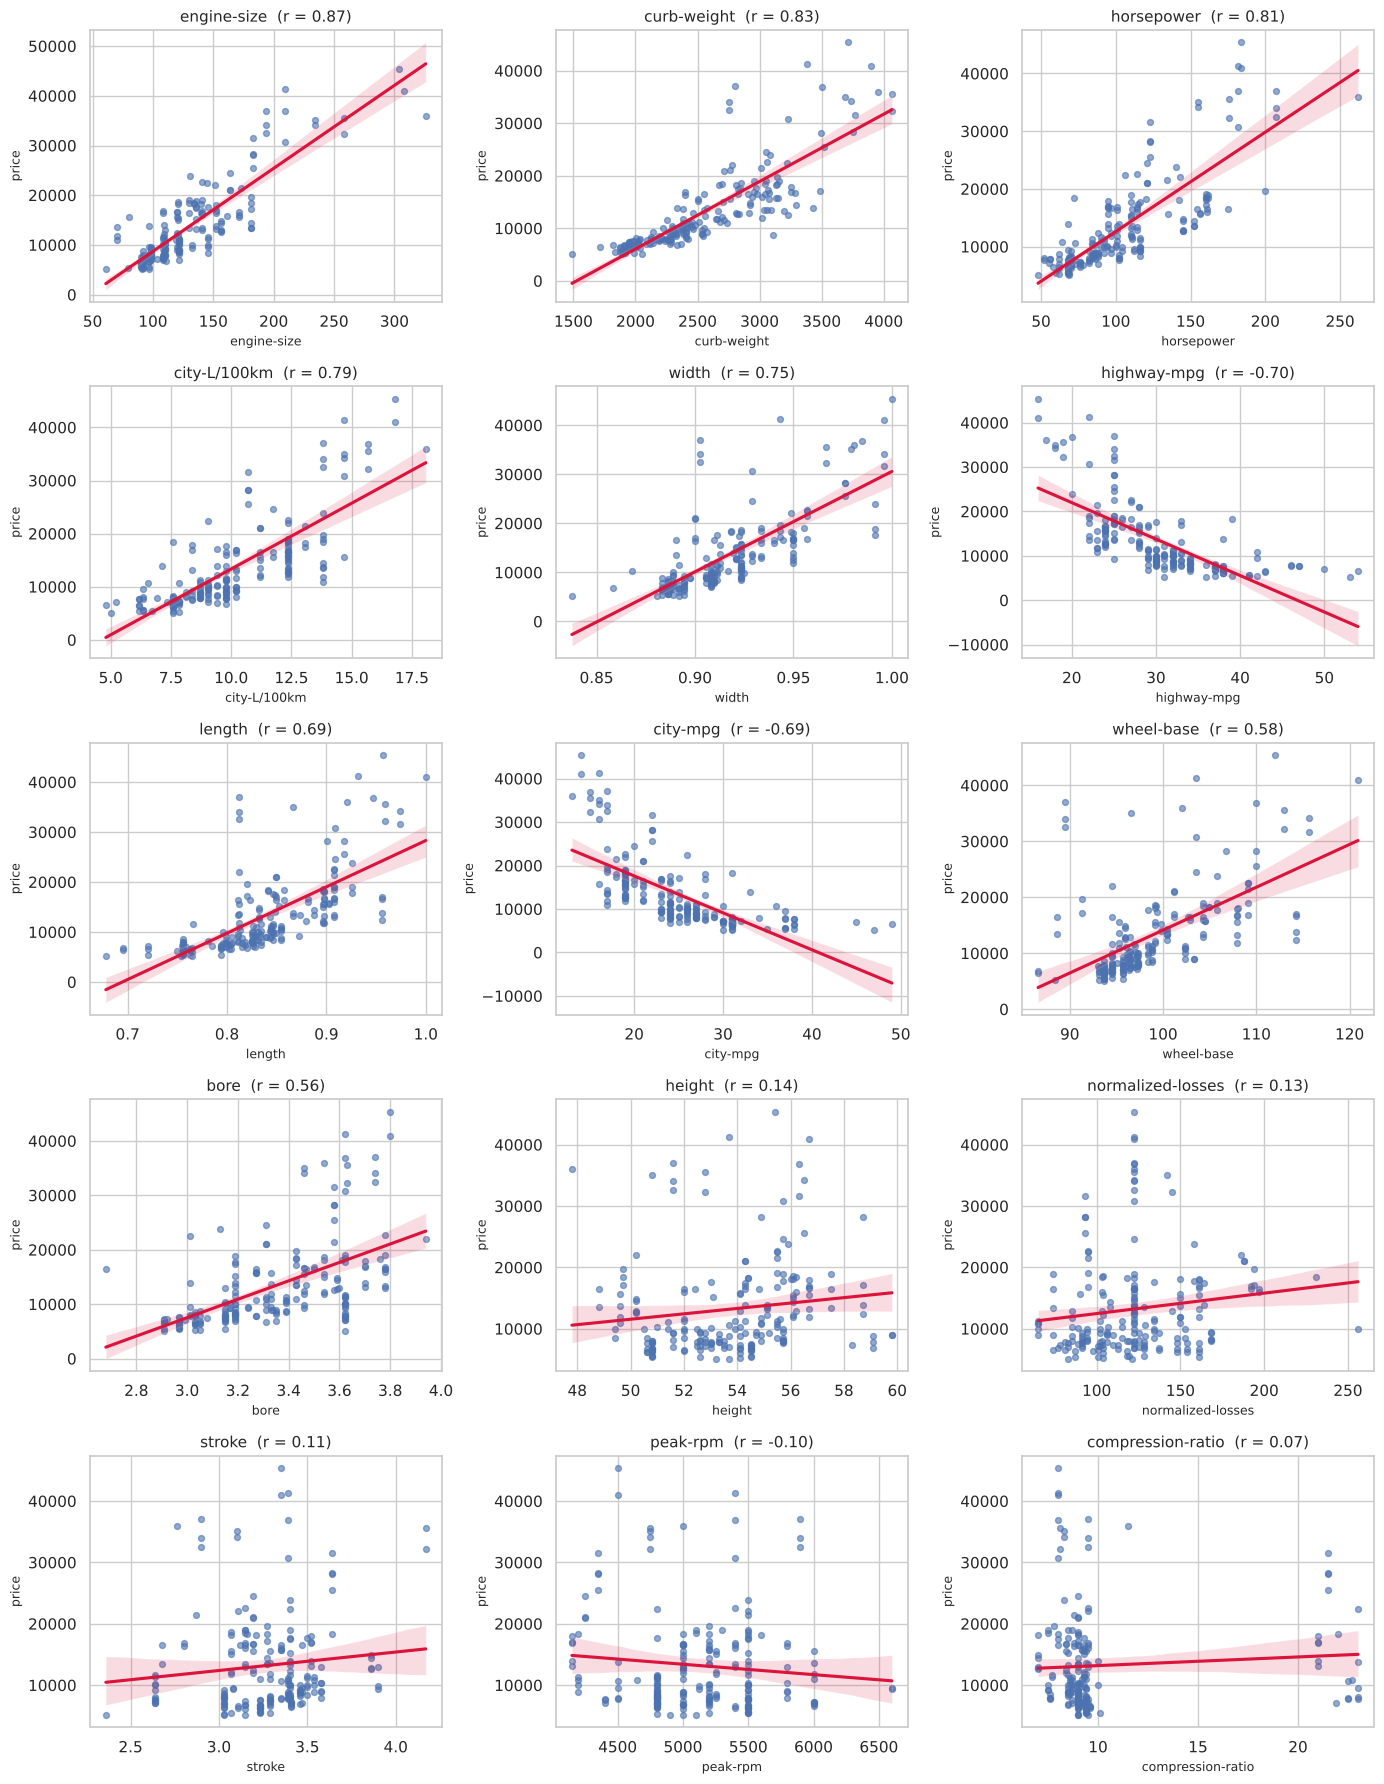

In [ ]:
feats = [c for c in CONT if c != 'price']
rows = []
for c in feats:
    r, p = stats.pearsonr(df[c], df['price']); rho, p2 = stats.spearmanr(df[c], df['price'])
    rows.append([c, r, p, rho, p2])
corr = pd.DataFrame(rows, columns=['variable', 'pearson r', 'p-value', 'spearman rho', 'spearman p']).set_index('variable')
corr['|r|'] = corr['pearson r'].abs()
corr['strength'] = pd.cut(corr['|r|'], [0, .3, .5, .7, .85, 1], labels=['negligible/weak', 'weak-moderate', 'moderate', 'strong', 'very strong'])
corr = corr.sort_values('|r|', ascending=False); display(corr.round(4))

fig, axes = plt.subplots(5, 3, figsize=(14, 18))
for ax, c in zip(axes.ravel(), corr.index):
    sns.regplot(x=c, y='price', data=df, ax=ax, scatter_kws={'s': 18, 'alpha': .6}, line_kws={'color': 'crimson'})
    ax.set_title(f"{c}  (r = {corr.loc[c, 'pearson r']:.2f})"); ax.set_ylabel('price')
plt.tight_layout(); plt.show()

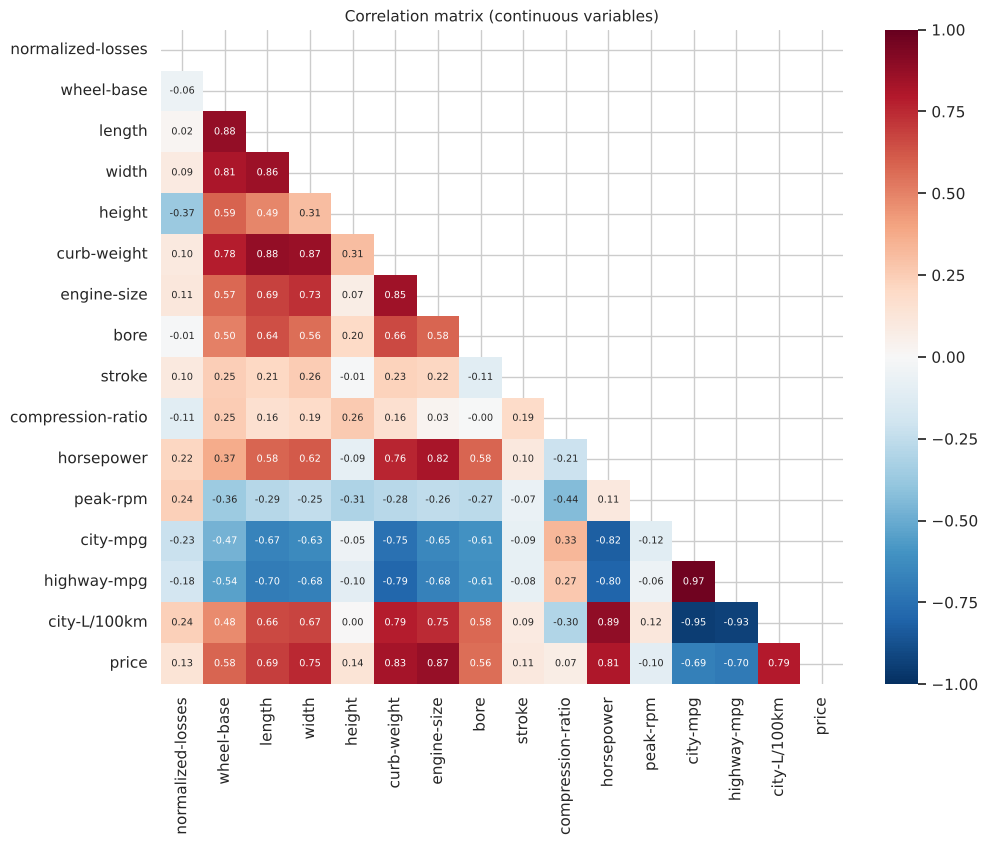

,level_0,level_1,r
205,city-mpg,highway-mpg,0.972
206,city-mpg,city-L/100km,-0.950
222,highway-mpg,city-L/100km,-0.930
174,horsepower,city-L/100km,0.889
37,length,curb-weight,0.881
18,wheel-base,length,0.876
53,width,curb-weight,0.866
35,length,width,0.857


In [ ]:
plt.figure(figsize=(11, 8.5))
cm = df[CONT].corr(); mask = np.triu(np.ones_like(cm, dtype=bool))
sns.heatmap(cm, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot_kws={'size': 7}); plt.title('Correlation matrix (continuous variables)'); plt.show()

pairs = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().rename('r').reset_index()
display(pairs[(pairs['r'].abs() > .85) & (pairs['level_0'] != 'price') & (pairs['level_1'] != 'price')].sort_values('r', key=abs, ascending=False).round(3).head(12))

**Continuous variables vs price**

- **Strong positive:** `engine-size` (r = 0.87), `curb-weight` (0.83), `horsepower` (0.81), `city-L/100km` (0.79), `width` (0.75).
- **Moderate:** `length` (0.69), `wheel-base` (0.58), `bore` (0.56).
- **Negative:** `highway-mpg` (−0.70) and `city-mpg` (−0.69): bigger, more powerful cars burn more fuel and cost more.
- **Negligible:** `height`, `normalized-losses`, `stroke`, `peak-rpm` and `compression-ratio` (|r| ≤ 0.14; Pearson p-values above 0.05 for all five). `height` and `normalized-losses` are borderline (p ≈ 0.055 and 0.058) and Spearman shows a weak monotone link, but the effect is tiny.
- Spearman agrees with the ranking; `curb-weight` (ρ = 0.91) is the most consistent monotone relationship, and the scatter plots show some curvature at high prices.

**Multicollinearity warning:** many predictors measure the same thing (city-mpg and highway-mpg r = 0.97; horsepower and city-L/100km 0.89; length and curb-weight 0.88; wheel-base and length 0.88). So the correlations above overlap, and a feature-selection step is needed to see which variables add independent information (Q5). Correlation also does not prove that a variable *causes* a higher price.

### 4(b) Categorical variables vs price (2 marks)

,levels,ANOVA F,ANOVA p,Kruskal H,Kruskal p,eta²
variable,,,,,,
make,22,33.2321,0.0000,124.2139,0.0000,0.7959
num-of-cylinders,7,54.9437,0.0000,80.8646,0.0000,0.6295
horsepower-binned,3,108.5048,0.0000,103.2578,0.0000,0.5229
drive-wheels,3,67.9541,0.0000,93.1889,0.0000,0.4070
fuel-system,8,15.0244,0.0000,122.5969,0.0000,0.3527
engine-type,6,9.8451,0.0000,38.0393,0.0000,0.2016
body-style,5,9.1288,0.0000,25.0231,0.0000,0.1570
symboling,6,6.8480,0.0000,57.0755,0.0000,0.1494
engine-location,2,24.4956,0.0000,7.7293,0.0054,0.1096


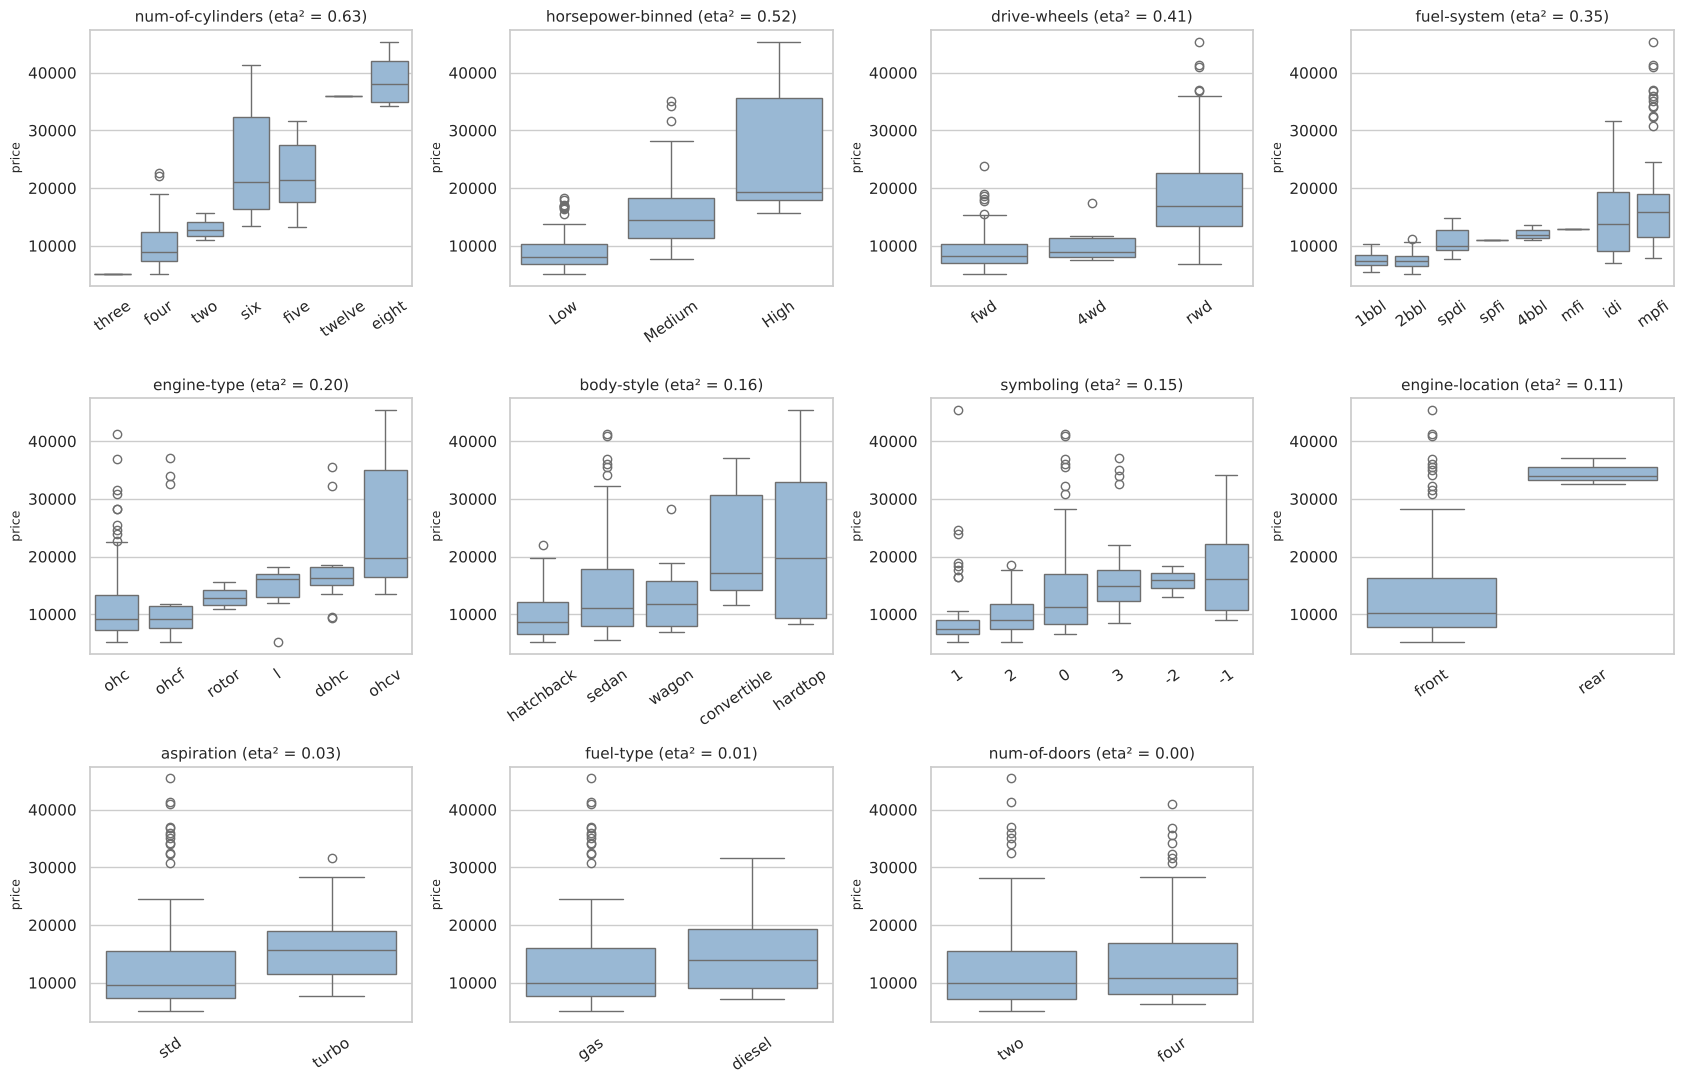

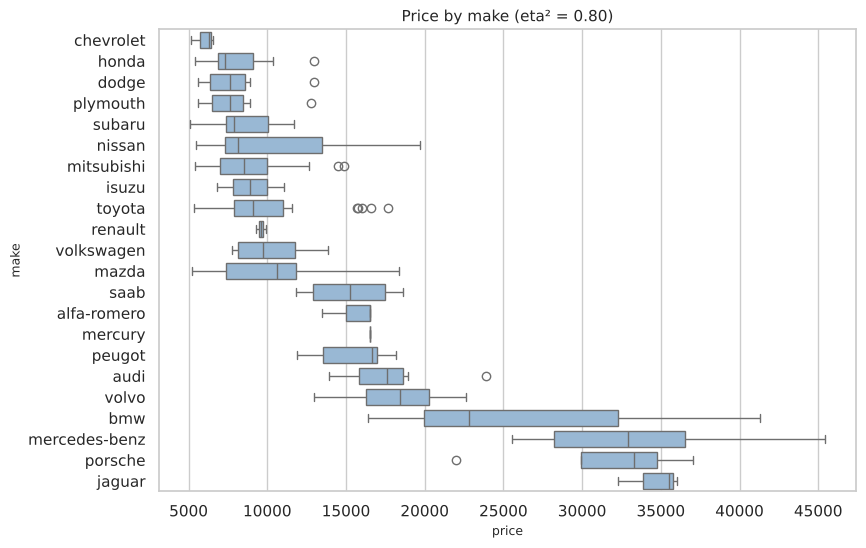

In [ ]:
def eta_squared(groups):
    allv = np.concatenate(groups); gm = allv.mean()
    ssb = sum(len(g) * (g.mean() - gm) ** 2 for g in groups); sst = ((allv - gm) ** 2).sum(); return ssb / sst

rows = []
for c in CATS:
    groups = [g['price'].values for _, g in df.groupby(c)]
    F, p = stats.f_oneway(*groups); H, pk = stats.kruskal(*groups)
    rows.append([c, len(groups), F, p, H, pk, eta_squared(groups)])
anova = pd.DataFrame(rows, columns=['variable', 'levels', 'ANOVA F', 'ANOVA p', 'Kruskal H', 'Kruskal p', 'eta²']).set_index('variable').sort_values('eta²', ascending=False)
display(anova.round(4))

fig, axes = plt.subplots(3, 4, figsize=(17, 11)); others = [c for c in anova.index if c != 'make']
for ax, c in zip(axes.ravel(), others):
    order = df.groupby(c)['price'].median().sort_values().index
    sns.boxplot(x=c, y='price', data=df, order=order, ax=ax, color='#8fb8de'); ax.set_title(f"{c} (eta² = {anova.loc[c, 'eta²']:.2f})"); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=35)
for ax in axes.ravel()[len(others):]: ax.axis('off')
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 6)); order = df.groupby('make')['price'].median().sort_values().index
sns.boxplot(y='make', x='price', data=df, order=order, color='#8fb8de'); plt.title(f"Price by make (eta² = {anova.loc['make','eta²']:.2f})"); plt.show()

In [ ]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
for c in ['drive-wheels', 'body-style']:
    print(f'Tukey HSD post-hoc: {c}'); print(pairwise_tukeyhsd(df['price'], df[c]).summary()); print()

Tukey HSD post-hoc: drive-wheels
    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
group1 group2  meandiff  p-adj    lower      upper    reject
------------------------------------------------------------
   4wd    fwd  -996.2203 0.8974 -6302.5087   4310.068  False
   4wd    rwd  9516.6133 0.0001  4114.6082 14918.6184   True
   fwd    rwd 10512.8337    0.0  8367.9755 12657.6919   True
------------------------------------------------------------

Tukey HSD post-hoc: body-style


         Multiple Comparison of Means - Tukey HSD, FWER=0.05          
   group1     group2    meandiff  p-adj     lower      upper    reject
----------------------------------------------------------------------
convertible   hardtop       318.0    1.0 -10641.7206 11277.7206  False
convertible hatchback -11933.0588 0.0018 -20575.6081 -3290.5096   True
convertible     sedan  -7430.7447 0.1212 -15975.8326  1114.3432  False
convertible     wagon    -9518.54 0.0395 -18744.0695  -293.0105   True
    hardtop hatchback -12251.0588 0.0001 -19836.1959 -4665.9218   True
    hardtop     sedan  -7748.7447  0.038 -15222.6441  -274.8452   True
    hardtop     wagon    -9836.54 0.0105 -18079.7821 -1593.2979   True
  hatchback     sedan   4502.3141 0.0016   1271.6247  7733.0036   True
  hatchback     wagon   2414.5188  0.628   -2331.977  7161.0146  False
      sedan     wagon  -2087.7953 0.7167  -6654.4233  2478.8327  False
----------------------------------------------------------------------



**Categorical variables vs price** (η² = share of price variance explained by the grouping)

| Variable | η² | Verdict |
|---|---|---|
| `make` | 0.80 | Very strong (but 22 levels, several tiny) |
| `num-of-cylinders` | 0.63 | Strong |
| `horsepower-binned` | 0.52 | Strong, but derived from horsepower |
| `drive-wheels` | 0.41 | Strong |
| `fuel-system` | 0.35 | Moderate (mostly reflects engine class) |
| `engine-type` | 0.20 | Moderate |
| `body-style` | 0.16 | Moderate |
| `symboling` | 0.15 | Moderate |
| `engine-location` | 0.11 | Significant but only 3 rear-engine cars |
| `aspiration` | 0.03 | Small |
| `fuel-type` | 0.01 | **Not significant** (ANOVA p = 0.12) |
| `num-of-doors` | 0.002 | **Not significant** (p = 0.55) |

- ANOVA and the rank-based Kruskal–Wallis test agree (the Kruskal test puts `fuel-type` marginally significant at p = 0.04 but with a trivial effect).
- **Tukey post-hoc, drive-wheels:** rwd is about 10,500 dearer than fwd and about 9,500 dearer than 4wd (both significant); fwd vs 4wd is *not* significant (p = 0.90).
- **Tukey post-hoc, body-style:** hatchbacks are significantly cheaper than sedans (≈ 4,500 less), hardtops and convertibles; hardtop vs convertible, sedan vs wagon and hatchback vs wagon are not significantly different.

### 4(c) Two categorical variables (1 mark)

drive-wheels,4wd,fwd,rwd
body-style,,,
convertible,0,1,5
hardtop,0,1,7
hatchback,1,49,18
sedan,3,55,36
wagon,4,12,9


Chi-square = 29.11, dof = 8, p = 3.03e-04; Cramér V (bias-corrected) = 0.230
Cells with expected count < 5: 9 of 15  (chi-square approximation is rough for those cells)


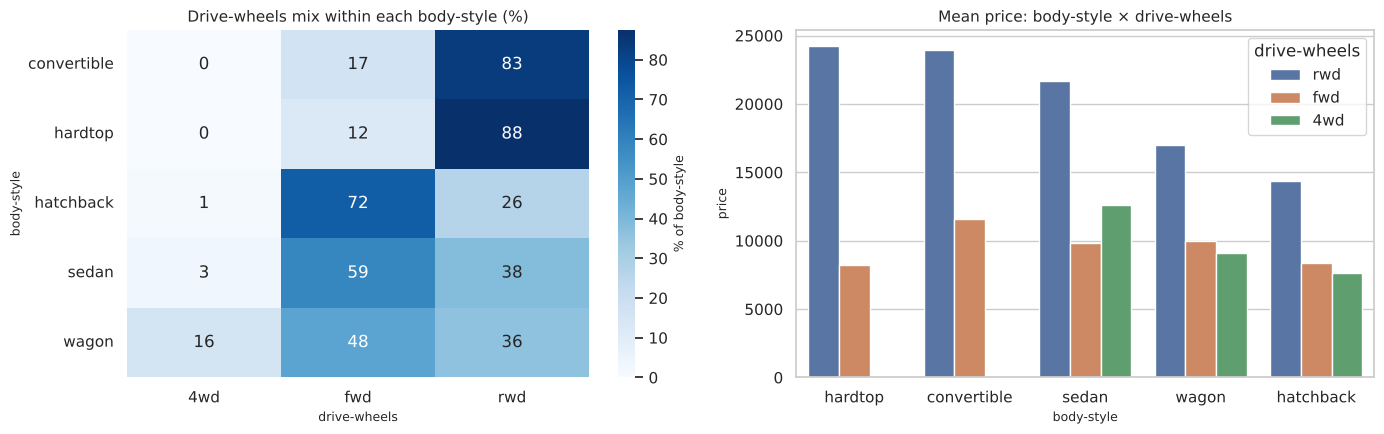

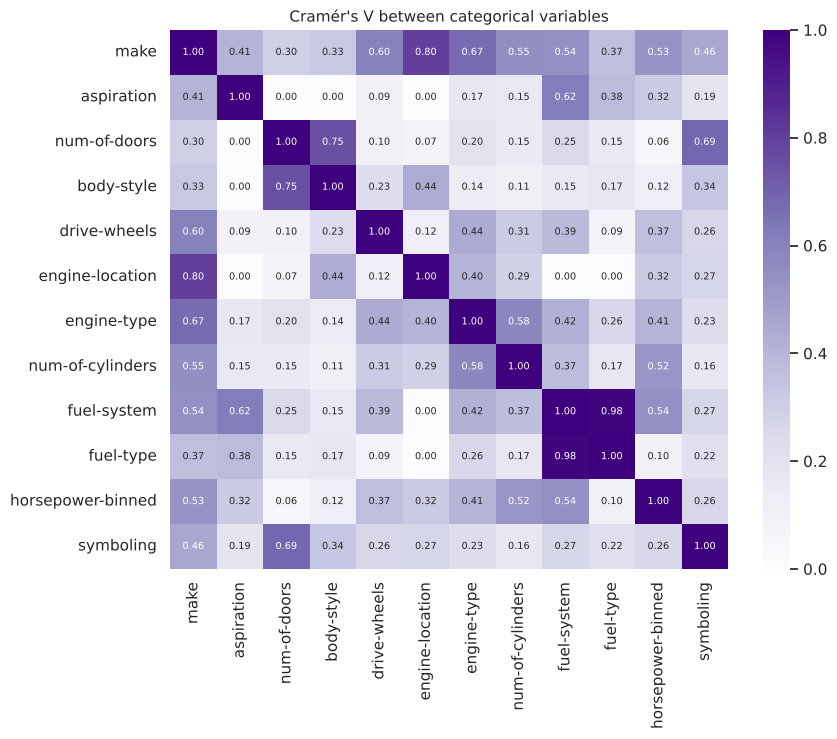

In [ ]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum(); r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1)); rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(kc - 1, rc - 1))

ct = pd.crosstab(df['body-style'], df['drive-wheels']); display(ct)
chi2, p, dof, exp = stats.chi2_contingency(ct)
print(f'Chi-square = {chi2:.2f}, dof = {dof}, p = {p:.2e}; Cramér V (bias-corrected) = {cramers_v(df["body-style"], df["drive-wheels"]):.3f}')
print(f'Cells with expected count < 5: {(exp < 5).sum()} of {exp.size}  (chi-square approximation is rough for those cells)')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(pd.crosstab(df['body-style'], df['drive-wheels'], normalize='index').mul(100), annot=True, fmt='.0f', cmap='Blues', ax=ax[0], cbar_kws={'label': '% of body-style'}); ax[0].set_title('Drive-wheels mix within each body-style (%)')
sns.barplot(x='body-style', y='price', hue='drive-wheels', data=df, ax=ax[1], errorbar=None, order=g_body.index); ax[1].set_title('Mean price: body-style × drive-wheels')
plt.tight_layout(); plt.show()

# association strength between all pairs of categorical variables
cv = pd.DataFrame(index=CATS, columns=CATS, dtype=float)
for a in CATS:
    for b in CATS: cv.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])
plt.figure(figsize=(9, 7)); sns.heatmap(cv.astype(float), annot=True, fmt='.2f', cmap='Purples', annot_kws={'size': 7}, vmin=0, vmax=1); plt.title("Cramér's V between categorical variables"); plt.show()

**Body-style and drive-wheels are associated** (χ² = 29.1, 8 df, p = 0.0003; bias-corrected Cramér's V = 0.23, a weak-to-moderate link).

- Convertibles (5 of 6) and hardtops (7 of 8) are almost all **rear-wheel drive**; hatchbacks (72%) and sedans (59%) are mostly **front-wheel drive**.
- Because the two variables overlap, part of the "convertible/hardtop price premium" in Q3 is really a rear-wheel-drive (sporty or luxury) premium. Within a body style, rwd is always dearer than fwd (right-hand chart).
- 9 of the 15 cells have expected counts below 5, so the p-value is approximate, but the pattern is clear in the percentages.

---
## Question 5 – Main price drivers, feature selection and recommendation (5 marks)
### 5.1 Candidate features
I exclude columns that merely duplicate another: `city-L/100km` (unit conversion of `city-mpg`), `gas`/`diesel` (replaced by one `fuel-type` label), `horsepower-binned` (derived from `horsepower`). That leaves 15 numeric (including the ordinal `symboling`) and 10 categorical candidates.

### 5.2 Three independent feature-selection methods
1. **Univariate strength** – |Pearson r| for numeric variables, correlation ratio √η² for categorical ones (both on a 0–1 scale).
2. **Mutual information** – captures non-linear dependence, and works for both types.
3. **Random-forest permutation importance** – how much cross-validated accuracy is lost when a feature is shuffled; this takes interactions into account and is computed on the *original* features, so one-hot dummies are not split up.

Random-forest 5-fold CV R² (all features): 0.880 ± 0.055


,univariate,mutual info,RF perm. importance (ΔR²),type,rank univariate,rank mutual,rank RF,mean rank
curb-weight,0.834,0.926,0.352,numeric,3.0,1.0,2.0,2.000
engine-size,0.872,0.772,0.406,numeric,2.0,4.0,1.0,2.333
horsepower,0.810,0.806,0.019,numeric,4.0,3.0,4.0,3.667
highway-mpg,0.705,0.835,0.034,numeric,7.0,2.0,3.0,4.000
width,0.751,0.661,0.018,numeric,6.0,6.0,5.0,5.667
make,0.892,0.528,0.004,categorical,1.0,8.0,9.0,6.000
city-mpg,0.687,0.725,0.004,numeric,9.0,5.0,8.0,7.333
length,0.691,0.579,0.005,numeric,8.0,7.0,7.0,7.333
wheel-base,0.585,0.473,0.011,numeric,12.0,9.0,6.0,9.000
drive-wheels,0.638,0.310,0.003,categorical,10.0,13.0,10.0,11.000


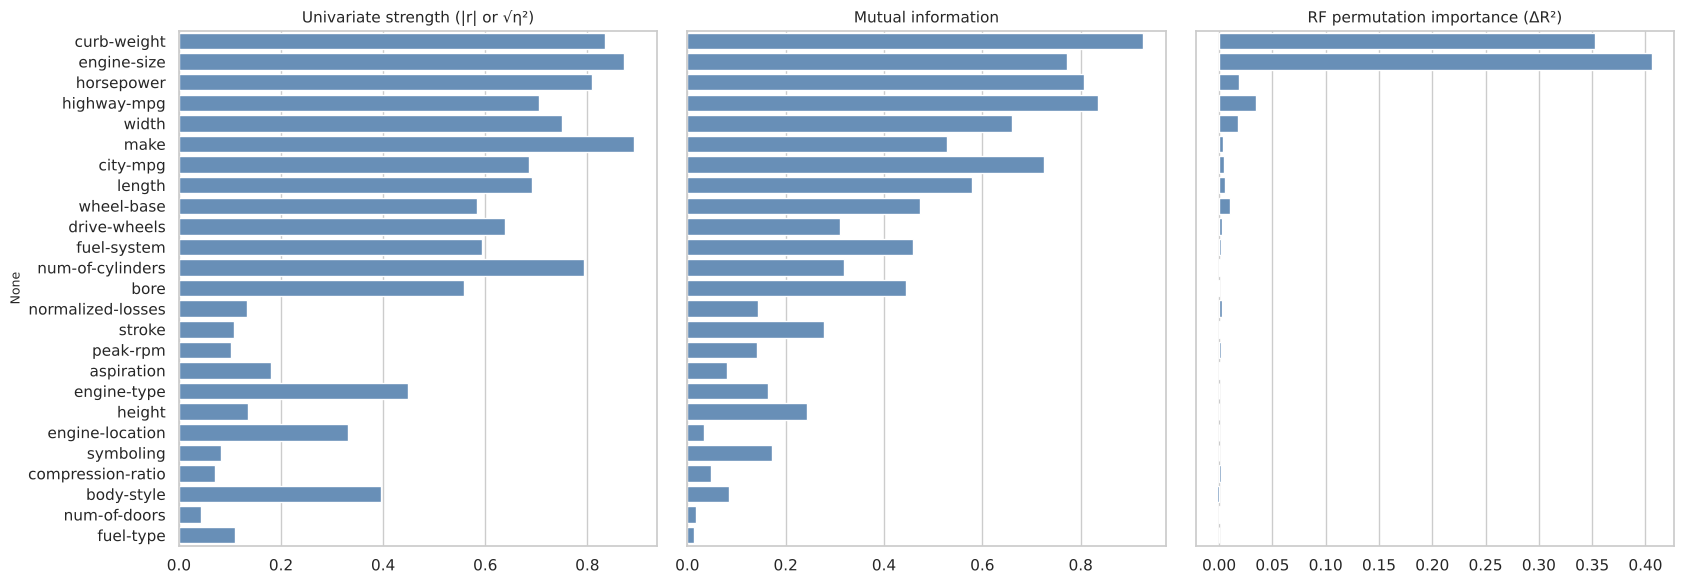

In [ ]:
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_regression

num_f = [c for c in CONT if c not in ('price', 'city-L/100km')] + ['symboling']
cat_f = ['make','aspiration','num-of-doors','body-style','drive-wheels','engine-location','engine-type','num-of-cylinders','fuel-system','fuel-type']
X, y = df[num_f + cat_f], df['price']

# --- method 1: univariate strength
uni = {c: abs(df[c].corr(df['price'])) for c in num_f}
uni.update({c: np.sqrt(anova.loc[c, 'eta²']) for c in cat_f})

# --- method 2: mutual information
Xo = X.copy(); Xo[cat_f] = OrdinalEncoder().fit_transform(X[cat_f])
mi = pd.Series(mutual_info_regression(Xo, y, discrete_features=[c in cat_f for c in X.columns], random_state=0, n_neighbors=5), index=X.columns)

# --- method 3: random-forest permutation importance, averaged over 5 CV folds
def make_rf(): return Pipeline([('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_f)], remainder='passthrough')),
                                ('rf', RandomForestRegressor(n_estimators=400, random_state=42, n_jobs=-1))])
perm, r2s = [], []
for tr, te in KFold(5, shuffle=True, random_state=42).split(X):
    m = make_rf().fit(X.iloc[tr], y.iloc[tr]); r2s.append(m.score(X.iloc[te], y.iloc[te]))
    pi = permutation_importance(m, X.iloc[te], y.iloc[te], n_repeats=10, random_state=0, scoring='r2'); perm.append(pi.importances_mean)
perm = pd.Series(np.mean(perm, axis=0), index=X.columns)
print('Random-forest 5-fold CV R² (all features): %.3f ± %.3f' % (np.mean(r2s), np.std(r2s)))

rank = pd.DataFrame({'univariate': pd.Series(uni), 'mutual info': mi, 'RF perm. importance (ΔR²)': perm})
rank['type'] = ['categorical' if c in cat_f else 'numeric' for c in rank.index]
for c in ['univariate', 'mutual info', 'RF perm. importance (ΔR²)']: rank['rank ' + c.split()[0]] = rank[c].rank(ascending=False)
rank['mean rank'] = rank[[c for c in rank.columns if c.startswith('rank ')]].mean(axis=1)
rank = rank.sort_values('mean rank'); display(rank.round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 6), sharey=True); order = rank.index
for a, col, t in zip(ax, ['univariate', 'mutual info', 'RF perm. importance (ΔR²)'], ['Univariate strength (|r| or √η²)', 'Mutual information', 'RF permutation importance (ΔR²)']):
    sns.barplot(x=rank[col].values, y=order, ax=a, color='#5b8fc4'); a.set_title(t)
plt.tight_layout(); plt.show()

**Which variables matter most?**

- Three methods give broadly the same top group: **curb-weight, engine-size, horsepower** (mean ranks 2.0, 2.3, 3.7), followed by `highway-mpg` and `width`.
- **Random-forest permutation importance** is dominated by `engine-size` (ΔR² = 0.41) and `curb-weight` (0.35); every other feature is below 0.04, so once those two are known the rest add little for a tree model.
- **Mutual information** ranks `curb-weight` first (0.93), then `highway-mpg` (0.84), `horsepower` (0.81) and `engine-size` (0.77), confirming non-linear dependence too.
- **`make`** is the strongest single categorical variable in the univariate test (√η² = 0.89), but ranks only 8th–9th in mutual information and the forest. A brand's price level is largely explained by the size and power of its cars, so brand mostly adds *extra* information on top of size, not instead of it. Permutation importance also splits credit between correlated variables, so it understates `make`, `num-of-cylinders` and `drive-wheels`, which are redundant with engine size.
- **Least useful:** `num-of-doors`, `fuel-type`, `body-style`, `symboling`, `compression-ratio`, `aspiration` and `engine-location`.
- The forest using all 25 features reaches a cross-validated **R² = 0.88 ± 0.06**.

### 5.3 Validation – how many features are really needed?
Features are added one at a time in order of mean rank; each subset is scored by repeated 5-fold cross-validation (R²) using a random forest and a ridge regression on log(price).

,feature added,RF R² (price),Ridge R² (log price)
k,,,
1,curb-weight,0.616,0.783
2,engine-size,0.865,0.797
3,horsepower,0.892,0.831
4,highway-mpg,0.898,0.830
5,width,0.908,0.837
6,make,0.914,0.918
7,city-mpg,0.913,0.918
8,length,0.911,0.917
9,wheel-base,0.912,0.916


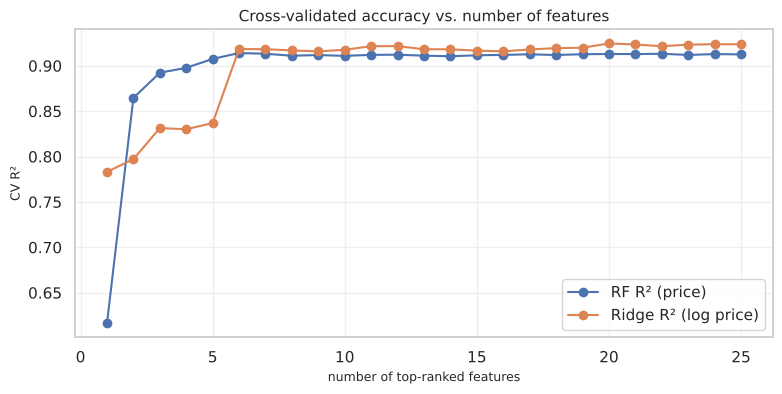

In [ ]:
ordered = list(rank.index); rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=1); curve = []
def make_ridge(cats): return Pipeline([('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cats)], remainder=StandardScaler())), ('m', Ridge(alpha=1.0))])
for k in range(1, len(ordered) + 1):
    f = ordered[:k]; cf = [c for c in f if c in cat_f]
    rf_k = Pipeline([('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cf)], remainder='passthrough')), ('rf', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))])
    r2_rf = cross_val_score(rf_k, X[f], y, cv=rkf, scoring='r2').mean()
    r2_rd = cross_val_score(make_ridge(cf), X[f], np.log(y), cv=rkf, scoring='r2').mean()
    curve.append([k, ordered[k - 1], r2_rf, r2_rd])
curve = pd.DataFrame(curve, columns=['k', 'feature added', 'RF R² (price)', 'Ridge R² (log price)']).set_index('k'); display(curve.round(3))
curve[['RF R² (price)', 'Ridge R² (log price)']].plot(marker='o', figsize=(9, 4)); plt.ylabel('CV R²'); plt.xlabel('number of top-ranked features'); plt.title('Cross-validated accuracy vs. number of features'); plt.grid(alpha=.3); plt.show()

**Validation**

- Random forest: the top **3 features** (curb-weight, engine-size, horsepower) already give CV R² = 0.89, the top 5 give 0.91, and adding the other 20 features does **not** improve it (it stays at about 0.91). So the other features carry essentially no additional price information.
- Ridge regression on log(price): five numeric features reach 0.84, and adding **`make`** lifts it to **0.92** (+0.08), the biggest jump after the first features. For a linear model, brand tier supplies information that size and power cannot, so brand is the fourth key driver.
- **Conclusion: the main price drivers are curb weight, engine size and horsepower (vehicle size and power), plus brand.** Width and highway-mpg are largely proxies for the same size/power effect.
- *Limitation:* the ranking was made on the full dataset and then cross-validated, so the R² values are slightly optimistic; with 201 rows the exact order of close features (e.g. curb-weight vs engine-size) is not stable.

In [ ]:
# Interpretable model on the selected drivers: effect on price in % (log-price OLS).
# Reference groups: drive_wheels = 4wd, body_style = convertible, make_tier = budget.
# make_tier = brands split into thirds by their median price (a simple brand-class proxy; it is derived from price, so read it as descriptive, not as an out-of-sample predictor).
import statsmodels.formula.api as smf
d = df.rename(columns=lambda c: c.replace('-', '_')).assign(log_price=np.log(df['price']))
SEL_FORMULA = 'log_price ~ engine_size + curb_weight + horsepower + C(drive_wheels) + C(body_style) + C(make_tier)'
tier = d.groupby('make')['price'].median()
d['make_tier'] = pd.qcut(d['make'].map(tier), 3, labels=['budget', 'mid', 'premium'])
ols = smf.ols(SEL_FORMULA, data=d).fit()
res = pd.DataFrame({'coef': ols.params, '% effect on price': (np.exp(ols.params) - 1) * 100, 'p-value': ols.pvalues}).round(4)
display(res.drop(index='Intercept')); print(f'R² = {ols.rsquared:.3f}   adj. R² = {ols.rsquared_adj:.3f}')

,coef,% effect on price,p-value
C(drive_wheels)[T.fwd],-0.0308,-3.0284,0.6106
C(drive_wheels)[T.rwd],-0.0128,-1.2686,0.8443
C(body_style)[T.hardtop],-0.1122,-10.6137,0.1923
C(body_style)[T.hatchback],-0.2204,-19.7817,0.0019
C(body_style)[T.sedan],-0.1537,-14.2460,0.0257
C(body_style)[T.wagon],-0.2576,-22.7091,0.0011
C(make_tier)[T.mid],0.0822,8.5660,0.0053
C(make_tier)[T.premium],0.3053,35.6982,0.0000
engine_size,0.0006,0.0597,0.3665
curb_weight,0.0004,0.0382,0.0000


R² = 0.907   adj. R² = 0.902


**What the interpretable model says** (log-price OLS, R² = 0.91; effects are in % and hold the other variables fixed; reference groups are convertible, 4wd and budget brands)

- **Curb weight:** about **+3.8% price per extra 100 lb** (p < 0.001).
- **Horsepower:** about **+4.6% per extra 10 hp** (p < 0.001).
- **Brand tier:** premium brands sell about **36% higher** than budget brands of similar size and power (p < 0.001); mid-tier brands about 9% higher (p = 0.005).
- **Body style:** compared with convertibles, hatchbacks are about 20% lower, wagons 23% and sedans 14% (hardtops 11% lower but not significant). The convertible reference group has only 6 cars, so treat these as approximate.
- **Not significant once the above are included:** `engine-size` (collinear with weight and horsepower) and `drive-wheels`. The big raw rwd gap in Q3 is largely because rwd cars are heavier, more powerful and more often from premium brands.

## Recommendation for a car dealer setting prices

1. **Start from size and power.** Curb weight, engine size and horsepower on their own explain about 89% of price variation (cross-validated), so use them to place a car in a price band.
2. **Then adjust for brand tier.** A premium badge is worth roughly a third more than a budget badge for the same size and power; mid-tier brands about 9%.
3. **Then adjust for body style.** Convertibles and hardtops carry a premium; hatchbacks and wagons sit about 20% below.
4. **Do not charge extra for drive-wheels as a separate item.** The rwd premium is mostly a size, power and brand effect.
5. **Ignore** number of doors, fuel type, compression ratio, symboling and normalized-losses when setting price: they add no independent information.
6. **Use fuel economy as a sanity check,** not a driver: efficient cars are cheaper because they are smaller and lighter.

**Limits:** only 201 cars from a single dataset, no age, mileage or condition, several rare brands (1–3 cars), and results are associations, not causes. Use the model as a starting point and check against local market prices.